# Лекция 4. Классификация и оценка качества моделей

**Дисциплина:** Анализ данных в Python  
**Тема:** Логистическая регрессия, деревья, ансамбли, метрики

В этом ноутбуке:
- Линейные модели: логистическая регрессия, SVM
- Деревья решений и случайный лес
- Градиентный бустинг
- Метрики: accuracy, precision, recall, F1, ROC-AUC
- Матрица ошибок и ROC-кривые
- Подбор гиперпараметров (GridSearchCV)

In [17]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, roc_auc_score, classification_report
)

sns.set_style('whitegrid')

In [18]:
# Загрузка данных
data = load_breast_cancer()
X, y = data.data, data.target
feature_names = data.feature_names
# Разделение
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (455, 30) | Test: (114, 30)


## 1. Обучение нескольких моделей

Сравним: логистическую регрессию, SVM, дерево решений, случайный лес,
градиентный бустинг.

In [19]:
# Список моделей
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=1000))
    ]),
    'SVM (RBF)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(kernel='rbf', probability=True, random_state=42))
    ]),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
}

# Обучаем каждую и записываем метрики
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    results.append({
        'Модель': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba),
    })

results_df = pd.DataFrame(results).round(4)
results_df

,Модель,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9954
1,SVM (RBF),0.9825,0.9861,0.9861,0.9861,0.9950
2,Decision Tree,0.9211,0.9565,0.9167,0.9362,0.9163
3,Random Forest,0.9561,0.9589,0.9722,0.9655,0.9937
4,Gradient Boosting,0.9561,0.9467,0.9861,0.9660,0.9907


## 2. Матрица ошибок

Матрица ошибок различает 4 исхода:
- **TP** (True Positive) — верно предсказан положительный класс;
- **TN** (True Negative) — верно предсказан отрицательный класс;
- **FP** (False Positive) — ложное срабатывание;
- **FN** (False Negative) — пропуск положительного класса.


Матрица ошибок:
[[39  3]
 [ 2 70]]


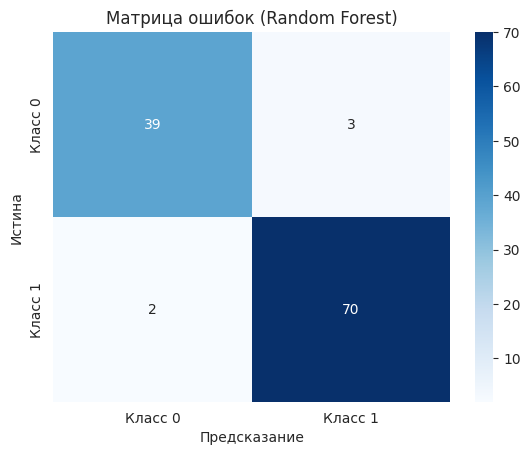

In [20]:
# Матрица ошибок для случайного леса
rf = models['Random Forest']
y_pred_rf = rf.predict(X_test)

# Базовые метрики Random Forest (нужны для сравнения)
f1_base  = f1_score(y_test, y_pred_rf)
auc_base = roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1])

cm = confusion_matrix(y_test, y_pred_rf)
print('\nМатрица ошибок:')
print(cm)

# Визуализация
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Класс 0', 'Класс 1'],
            yticklabels=['Класс 0', 'Класс 1'])
plt.title('Матрица ошибок (Random Forest)')
plt.ylabel('Истина')
plt.xlabel('Предсказание')
plt.show()

## 3. Метрики: precision, recall, F1

- **Precision** = TP / (TP + FP) — точность предсказания положительного класса;
- **Recall** = TP / (TP + FN) — полнота (насколько хорошо находим положительный класс);
- **F1** = 2 · (P · R) / (P + R) — гармоническое среднее.

In [21]:
# Полный classification_report
print(classification_report(y_test, y_pred_rf, target_names=['Класс 0', 'Класс 1']))

              precision    recall  f1-score   support

     Класс 0       0.95      0.93      0.94        42
     Класс 1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



## 4. ROC-кривая и ROC-AUC

ROC-кривая показывает зависимость TPR (True Positive Rate) от FPR (False Positive Rate)
при разных порогах классификации.  
AUC — площадь под кривой. Интерпретация: **0.5** — случайное угадывание, **1.0** — идеальный классификатор.

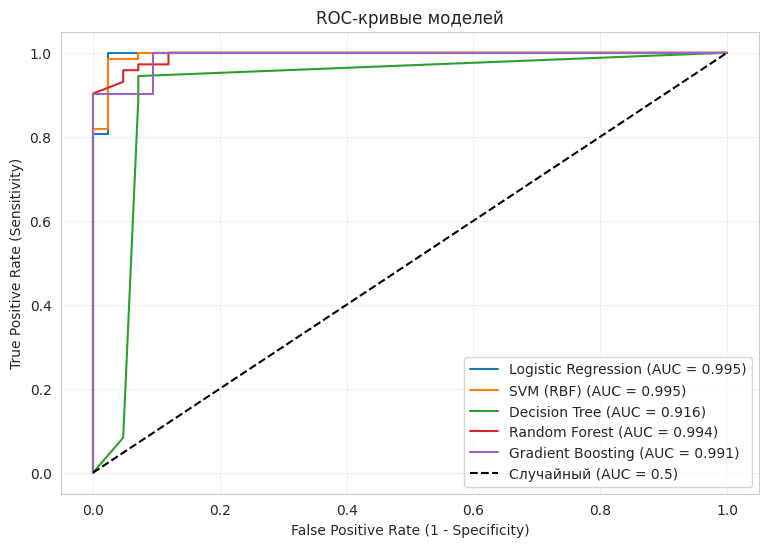

In [22]:
# ROC-кривые для всех моделей на одном графике
plt.figure(figsize=(9, 6))

for name, model in models.items():
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

# Линия случайного классификатора
plt.plot([0, 1], [0, 1], 'k--', label='Случайный (AUC = 0.5)')

plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC-кривые моделей')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

## 5. Подбор гиперпараметров (GridSearchCV)

Перебираем все комбинации заданных гиперпараметров и выбираем лучшие по метрике.

In [23]:
# Сетка гиперпараметров для случайного леса
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10],
}

gs = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

gs.fit(X_train, y_train)
best_rf = gs.best_estimator_
y_pred_best = best_rf.predict(X_test)

print('Лучшие параметры:', gs.best_params_)
print(f'Лучший F1 (CV): {gs.best_score_:.4f}')


Лучшие параметры: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Лучший F1 (CV): 0.9684


In [24]:
# Сравним базовую и настроенную модели
print('\nБазовая модель:')
print(f'  F1:      {f1_base:.4f}')
print(f'  ROC-AUC: {auc_base:.4f}')

print('\nНастроенная модель:')
print(f'  F1:      {f1_score(y_test, y_pred_best):.4f}')
print(f'  ROC-AUC: {roc_auc_score(y_test, best_rf.predict_proba(X_test)[:, 1]):.4f}')


Базовая модель:
  F1:      0.9655
  ROC-AUC: 0.9937

Настроенная модель:
  F1:      0.9655
  ROC-AUC: 0.9931


## 6. Важность признаков

Случайный лес позволяет оценить, какие признаки наиболее важны для предсказания.

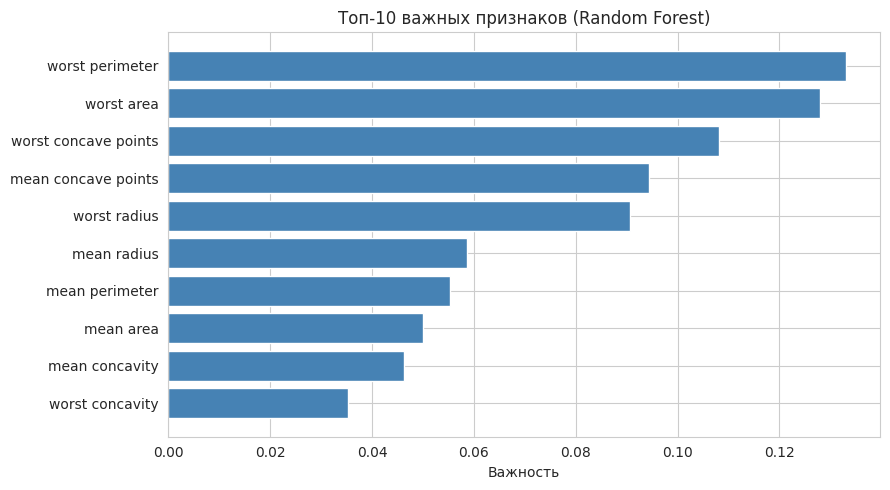

In [25]:
# Важность признаков в случайном лесу
importances = best_rf.feature_importances_

# Сортировка по убыванию
idx = np.argsort(importances)[::-1]

# Топ-10
top_n = 10
plt.figure(figsize=(9, 5))
plt.barh(
    [feature_names[i] for i in idx[:top_n]][::-1],
    importances[idx[:top_n]][::-1],
    color='steelblue'
)
plt.xlabel('Важность')
plt.title(f'Топ-{top_n} важных признаков (Random Forest)')
plt.tight_layout()
plt.show()

## Выводы по лекции 4

- Классификация — одна из основных задач ML.
- Логистическая регрессия и SVM — линейные модели, простые и интерпретируемые.
- Деревья решений дают нелинейные границы, но склонны к переобучению.
- Случайный лес (бэггинг) и градиентный бустинг — ансамбли, дают лучшее качество.
- Метрики: accuracy, precision, recall, F1, ROC-AUC.
- ROC-AUC — самая устойчивая метрика, не зависит от выбора порога.
- GridSearchCV позволяет автоматически подобрать гиперпараметры.